# Exploratory Data Analysis

**Input:** `train.csv`  the 150,000 loan stratified sample of 2007–2015 loans produced in notebook 01. 

**What this notebook does**
1. Profiles every variable: type, % missing (including disguised missing values), outliers, distribution, usefulness
2. Documents the data quirks the pipeline has to handle
3. Plots default rate by FICO, purpose, home ownership and year , with a one-line takeaway under every chart
4. Ends with a hand-off table: what the pipeline should do with each column

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

DATA_PATH = "../data/train.csv"

# Chart style: one accent color for default rates, a second for the "defaulted" class
BLUE, ORANGE, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#e6e5e0"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
})
pct = mtick.PercentFormatter(1.0, decimals=0)

df = pd.read_csv(DATA_PATH, low_memory=False)
df["issue_d"] = pd.to_datetime(df["issue_d"])
df["year"] = df["issue_d"].dt.year
BASE_RATE = df["Default"].mean()
print(f"{df.shape[0]:,} loans x {df.shape[1] - 1} columns | issued {df.issue_d.min():%b %Y} – {df.issue_d.max():%b %Y}")
print(f"Overall default rate: {BASE_RATE:.1%}")

150,000 loans x 15 columns | issued Jun 2007 – Dec 2015
Overall default rate: 18.5%


**Takeaway:** 18.5% of training loans defaulted, so the classes are imbalanced. Accuracy would be misleading, a model that approves everyone is 81.5% accurate. 

## 1. Variable dictionary

| Column | Meaning |
|---|---|
| `id` | Loan ID |
| `issue_d` | Month the loan was issued |
| `revenue` | Borrower's self-reported **annual income** (USD) |
| `dti_n` | Debt-to-income ratio (%): monthly debt payments / monthly income, excluding this loan |
| `loan_amnt` | Amount requested (USD) |
| `fico_n` | FICO credit score (midpoint of the reported range) |
| `experience_c` | Binary borrower-experience flag |
| `emp_length` | Years employed (`NI` = not informed) |
| `purpose` | Loan purpose chosen from a fixed list |
| `home_ownership_n` | RENT / MORTGAGE / OWN / OTHER |
| `addr_state`, `zip_code` | State and first 3 digits of ZIP code |
| `title`, `desc` | Free-text loan title and description written by the borrower |
| `Default` | **Target**: 1 = charged off, 0 = fully paid |

## 2. Profile of every variable

In [2]:
def profile(data, exclude=("year",)):
    rows = []
    for col in data.columns.drop(list(exclude)):
        s = data[col]
        num = pd.api.types.is_numeric_dtype(s) and col not in ("id", "Default")
        disguised = (s == "NI").mean() if s.dtype == object or pd.api.types.is_string_dtype(s) else 0.0
        row = {
            "column": col,
            "type": "numeric" if num else ("datetime" if col == "issue_d" else ("id" if col == "id" else ("target" if col == "Default" else "categorical/text"))),
            "% missing (NaN)": s.isna().mean(),
            "% disguised missing ('NI')": disguised,
            "n unique": s.nunique(),
            "top value share": s.value_counts(normalize=True).iloc[0],
        }
        if num:
            q1, q3 = s.quantile([.25, .75])
            iqr = q3 - q1
            row.update({
                "min": s.min(), "median": s.median(), "max": s.max(), "skew": s.skew(),
                "% outliers (1.5×IQR)": ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).mean(),
            })
        rows.append(row)
    return pd.DataFrame(rows).set_index("column")

prof = profile(df)
usefulness = {
    "id": "None — identifier (drop)",
    "issue_d": "Used for the time split only; not a feature",
    "revenue": "Medium — higher income, lower default; needs log",
    "dti_n": "High — default rises steadily with DTI",
    "loan_amnt": "Low alone, high as loan-to-income ratio",
    "fico_n": "High — strongest single predictor",
    "experience_c": "None — almost constant (drop)",
    "emp_length": "Low — flat, except 'NI' which is riskier",
    "purpose": "Medium — small_business vs car differ 2x",
    "home_ownership_n": "Medium — renters riskier than mortgage holders",
    "addr_state": "Low/medium — 50 levels, mostly small differences",
    "zip_code": "Low — 879 levels, many tiny groups (overfit risk)",
    "title": "None — free text duplicating purpose (drop)",
    "desc": "None — 86% missing, absent after 2014 (drop)",
    "Default": "Target",
}
prof["usefulness"] = pd.Series(usefulness)
fmt = {c: "{:.1%}" for c in ["% missing (NaN)", "% disguised missing ('NI')", "top value share", "% outliers (1.5×IQR)"]}
fmt.update({"min": "{:,.1f}", "median": "{:,.1f}", "max": "{:,.1f}", "skew": "{:.2f}", "n unique": "{:,}"})
prof.style.format(fmt, na_rep="")

,type,% missing (NaN),% disguised missing ('NI'),n unique,top value share,min,median,max,skew,% outliers (1.5×IQR),usefulness
column,,,,,,,,,,,
id,id,0.0%,0.0%,"150,000",0.0%,,,,,,None — identifier (drop)
issue_d,datetime,0.0%,0.0%,103,5.2%,,,,,,Used for the time split only; not a feature
revenue,numeric,0.0%,0.0%,"12,671",3.8%,"2,000.0","63,500.0","9,500,000.0",46.42,4.4%,"Medium — higher income, lower default; needs log"
dti_n,numeric,0.0%,0.0%,"4,010",0.1%,0.0,17.5,83.4,0.24,0.0%,High — default rises steadily with DTI
loan_amnt,numeric,0.0%,0.0%,"1,337",7.1%,500.0,"12,000.0","35,000.0",0.73,0.0%,"Low alone, high as loan-to-income ratio"
fico_n,numeric,0.0%,0.0%,46,9.0%,612.0,692.0,847.5,1.30,3.0%,High — strongest single predictor
experience_c,numeric,0.0%,0.0%,2,100.0%,0.0,1.0,1.0,-173.20,0.0%,None — almost constant (drop)
emp_length,categorical/text,0.0%,5.2%,12,32.4%,,,,,,"Low — flat, except 'NI' which is riskier"
purpose,categorical/text,0.0%,0.0%,14,58.8%,,,,,,Medium — small_business vs car differ 2x


Only `desc` (and a handful of `title` rows) has real NaNs, so `isna()` alone would wrongly suggest the data is complete. The real missingness hides in `emp_length = "NI"`. Among numeric columns, `revenue` is extremely skewed (skew ≈ 46), while `fico_n`, `dti_n` and `loan_amnt` are well-behaved.

## 3. Data quirks the pipeline must handle

### 3.1 `emp_length = NI` is a disguised missing value, and it carries signal

In [3]:
emp = df.assign(is_NI=df.emp_length.eq("NI")).groupby("is_NI").agg(
    loans=("Default", "size"), default_rate=("Default", "mean"), median_income=("revenue", "median"))
emp.index = ["Employment length reported", "NI (not informed)"]
emp.style.format({"loans": "{:,}", "default_rate": "{:.1%}", "median_income": "${:,.0f}"})

,loans,default_rate,median_income
Employment length reported,"142,213",18.2%,"$65,000"
NI (not informed),"7,787",23.7%,"$45,000"


5.2% of borrowers did not report employment length, and they default at 23.7% vs 18.2% for everyone else, with lower median income ($45k vs $65k). The missingness is informative, so **keep "NI" as its own category / add an `emp_missing` flag** rather than imputing it away.

### 3.2 `experience_c` is nearly constant

In [4]:
print(df.experience_c.value_counts().to_string())
print("\nYears of the rows with experience_c = 0:", sorted(df.loc[df.experience_c == 0, "year"].unique()))

experience_c
1    149995
0         5

Years of the rows with experience_c = 0: [np.int32(2007)]


Only 5 of 150,000 loans (0.003%) have `experience_c = 0`, all issued in 2007, the platform's first year. 

### 3.3 Income (`revenue`) is heavily right-skewed with extreme values

Income percentiles:
0.010     $18,000
0.250     $45,000
0.500     $63,500
0.750     $90,000
0.990    $250,000
0.999    $500,010

Max income: $9,500,000   |   loans with income > $500k: 150
Skew raw: 46.4   →   skew of log(income): 0.18


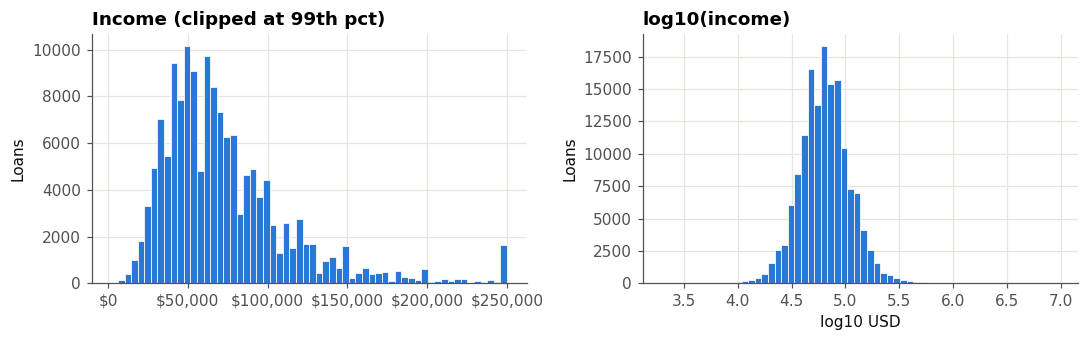

In [5]:
q = df.revenue.quantile([.01, .25, .5, .75, .99, .999])
print("Income percentiles:"); print(q.map("${:,.0f}".format).to_string())
print(f"\nMax income: ${df.revenue.max():,.0f}   |   loans with income > $500k: {(df.revenue > 500_000).sum()}")
print(f"Skew raw: {df.revenue.skew():.1f}   →   skew of log(income): {np.log1p(df.revenue).skew():.2f}")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
axes[0].hist(df.revenue.clip(upper=df.revenue.quantile(.99)), bins=60, color=BLUE, edgecolor="white", linewidth=0.5)
axes[0].set_title("Income (clipped at 99th pct)"); axes[0].xaxis.set_major_formatter(mtick.StrMethodFormatter("${x:,.0f}"))
axes[1].hist(np.log10(df.revenue), bins=60, color=BLUE, edgecolor="white", linewidth=0.5)
axes[1].set_title("log10(income)"); axes[1].set_xlabel("log10 USD")
for ax in axes: ax.set_ylabel("Loans")
plt.tight_layout(); plt.show()

Median income is USD 63.5k, while max income is USD 9.5M (skew ≈ 46). A log transform makes it almost symmetric (skew ≈ 0.18). The very top values are likely self-reported errors, so **log-transform and cap at the 99.9th percentile** (≈ USD 500k) inside the pipeline.

### 3.4 DTI has a few implausible values

In [6]:
print(f"DTI = 0: {(df.dti_n == 0).sum()} loans   |   DTI > 40: {(df.dti_n > 40).sum()} loans   |   max: {df.dti_n.max()}")
print(f"99th percentile: {df.dti_n.quantile(.99):.1f}")

DTI = 0: 83 loans   |   DTI > 40: 13 loans   |   max: 83.4
99th percentile: 37.3


99% of borrowers have DTI below 37%, but 13 loans exceed 40% (max 83%). They are too few to matter for tree models but can pull linear models, so **cap DTI at the 99.9th percentile**. The 83 loans with DTI = 0 are plausible and stay.

### 3.5 High-cardinality location columns

addr_state: 50 levels | smallest: {'ME': 83, 'ND': 83, 'ID': 1}
zip_code:   879 levels | median 84 loans per ZIP | 172 ZIPs (20%) have fewer than 30 loans


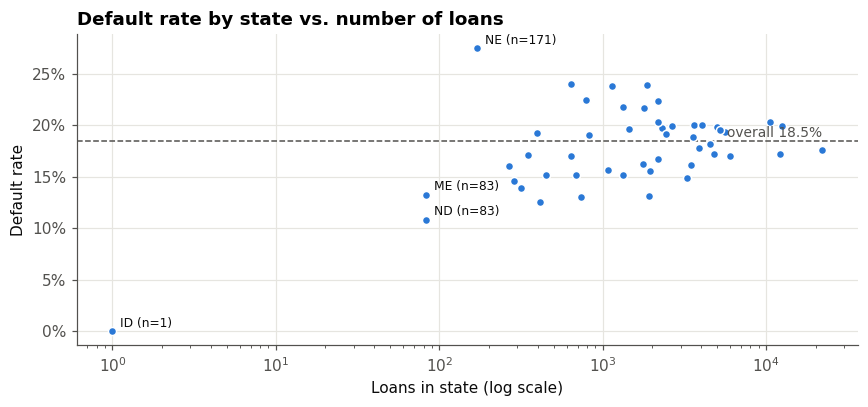

In [7]:
zip_counts = df.zip_code.value_counts()
state_counts = df.addr_state.value_counts()
print(f"addr_state: {df.addr_state.nunique()} levels | smallest: {state_counts.tail(3).to_dict()}")
print(f"zip_code:   {df.zip_code.nunique()} levels | median {zip_counts.median():.0f} loans per ZIP | "
      f"{(zip_counts < 30).sum()} ZIPs ({(zip_counts < 30).mean():.0%}) have fewer than 30 loans")

st = df.groupby("addr_state").Default.agg(rate="mean", n="size")
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.scatter(st.n, st.rate, s=28, color=BLUE, edgecolor="white", linewidth=1, zorder=3)
ax.axhline(BASE_RATE, color=MUTED, ls="--", lw=1)
ax.text(st.n.max(), BASE_RATE + .004, f"overall {BASE_RATE:.1%}", ha="right", color=MUTED, fontsize=9)
for s_, r in st[(st.n < 200) | ((st.rate - BASE_RATE).abs() > .07)].iterrows():
    ax.annotate(f"{s_} (n={int(r.n)})", (r.n, r.rate), xytext=(5, 3), textcoords="offset points", fontsize=8, color=INK)
ax.set_xscale("log"); ax.yaxis.set_major_formatter(pct)
ax.set_xlabel("Loans in state (log scale)"); ax.set_ylabel("Default rate")
ax.set_title("Default rate by state vs. number of loans")
plt.tight_layout(); plt.show()

The states with the most extreme default rates are the smallest ones (NE at 27%, ND and ME at 11–13%, ID with a single loan), while large states sit close to the 18.5% average. One-hot encoding 50 states would mostly fit noise. **Use smoothed target encoding or group rare levels for `addr_state`, and drop `zip_code`** (or encode it only with strong smoothing).

### 3.6 Free-text columns: `desc` disappears over time, `title` duplicates `purpose`

In [8]:
by_year_desc = df.groupby("year").desc.apply(lambda s: s.notna().mean())
print("Share of loans with a description, by year:"); print(by_year_desc.map("{:.0%}".format).to_string())
print(f"\ntitle: {df.title.nunique():,} unique values; most common (lower-cased):")
print(df.title.str.lower().value_counts().head(5).to_string())

Share of loans with a description, by year:
year
2007     0%
2008    36%
2009    85%
2010    60%
2011    55%
2012    59%
2013    36%
2014     7%
2015     0%

title: 14,254 unique values; most common (lower-cased):
title
debt consolidation         72407
credit card refinancing    27161
home improvement            7201
other                       5394
major purchase              2025


`desc` is 86% missing overall and essentially **0% filled after 2014** , so it would be completely empty in the 2016 test set, a model using it would learn a pattern that no longer exists. `title` is free text whose top values just repeat the `purpose` category. **Drop both.**

### 3.7 Small categories and the FICO floor

In [9]:
print(df.home_ownership_n.value_counts().to_string())
print("\nPurposes with < 500 loans:", df.purpose.value_counts().loc[lambda s: s < 500].to_dict())
print(f"\nFICO range: {df.fico_n.min()}–{df.fico_n.max()} | loans below 660: {(df.fico_n < 660).sum()}")

home_ownership_n
MORTGAGE    74067
RENT        61016
OWN         14863
OTHER          54

Purposes with < 500 loans: {'wedding': 390, 'renewable_energy': 87, 'educational': 75}

FICO range: 612.0–847.5 | loans below 660: 90


`home_ownership = OTHER` has only 54 loans and three purposes have fewer than 500, so their default rates are unreliable. FICO is effectively truncated at ~660 because Lending Club rejected applicants below that, so only 90 loans fall under it: **the model cannot say anything about sub-660 borrowers**, which belongs in the limitations.

## 4. Numeric features: defaulters vs. non-defaulters

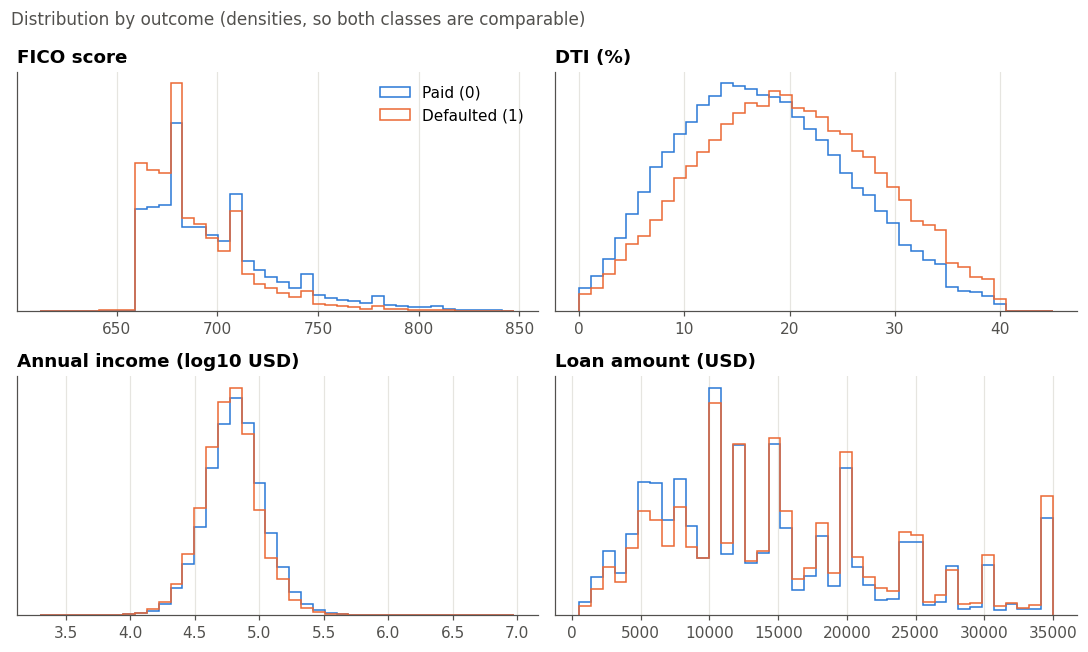

In [10]:
num_cols = {"fico_n": "FICO score", "dti_n": "DTI (%)", "revenue": "Annual income (log10 USD)", "loan_amnt": "Loan amount (USD)"}
fig, axes = plt.subplots(2, 2, figsize=(10, 6))
for ax, (col, label) in zip(axes.flat, num_cols.items()):
    x = np.log10(df[col]) if col == "revenue" else df[col]
    if col == "dti_n": x = x.clip(upper=45)
    bins = np.histogram_bin_edges(x, bins=40)
    for val, color, name in [(0, BLUE, "Paid (0)"), (1, ORANGE, "Defaulted (1)")]:
        ax.hist(x[df.Default == val], bins=bins, density=True, histtype="step", lw=2, color=color, label=name)
    ax.set_title(label); ax.set_yticks([]); ax.grid(axis="y", visible=False)
axes[0, 0].legend(frameon=False, loc="upper right")
fig.suptitle("Distribution by outcome (densities, so both classes are comparable)", x=0.01, ha="left", fontsize=11, color=MUTED)
plt.tight_layout(); plt.show()

Defaulters are shifted toward lower FICO and higher DTI, but the two distributions overlap heavily on every variable, single feature separates good from bad loans, so the model will need to combine them. Income and loan amount barely differ between classes on their own, which motivates the loan-to-income ratio in section 6.

## 5. Default rate by the four key dimensions

In [11]:
def rate_table(data, by):
    return data.groupby(by, observed=True).Default.agg(rate="mean", n="size")

def rate_bars(ax, t, title, horizontal=False, annotate=True):
    labels = [f"{i}\n(n={n:,})" if not horizontal else f"{i}  (n={n:,})" for i, n in zip(t.index, t.n)]
    if horizontal:
        ax.barh(labels, t.rate, color=BLUE, height=0.65)
        ax.axvline(BASE_RATE, color=MUTED, ls="--", lw=1); ax.xaxis.set_major_formatter(pct)
        for y, r in enumerate(t.rate): ax.text(r + .003, y, f"{r:.1%}", va="center", fontsize=8, color=INK)
        ax.grid(axis="y", visible=False); ax.set_xlabel("Default rate")
    else:
        ax.bar(labels, t.rate, color=BLUE, width=0.65)
        ax.axhline(BASE_RATE, color=MUTED, ls="--", lw=1); ax.yaxis.set_major_formatter(pct)
        if annotate:
            for x, r in enumerate(t.rate): ax.text(x, r + .004, f"{r:.1%}", ha="center", fontsize=8, color=INK)
        ax.grid(axis="x", visible=False); ax.set_ylabel("Default rate")
    ax.set_title(title)

### 5.1 FICO score

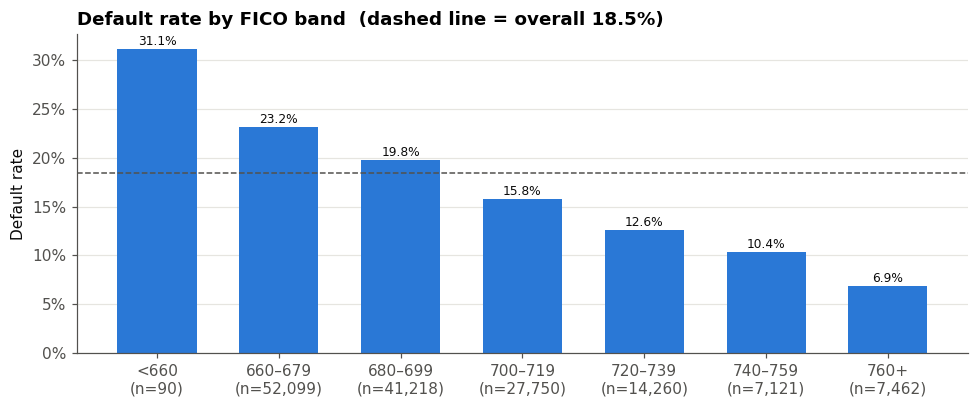

In [12]:
df["fico_band"] = pd.cut(df.fico_n, [0, 659, 679, 699, 719, 739, 759, 900],
                         labels=["<660", "660–679", "680–699", "700–719", "720–739", "740–759", "760+"])
fig, ax = plt.subplots(figsize=(9, 3.8))
rate_bars(ax, rate_table(df, "fico_band"), "Default rate by FICO band  (dashed line = overall 18.5%)")
plt.tight_layout(); plt.show()

Default rate falls steadily from 23% to 7%, FICO is the strongest single signal, which is why a FICO-only logistic regression is the right baseline. (The 31% for <660 rests on only 90 loans.)

### 5.2 Loan purpose

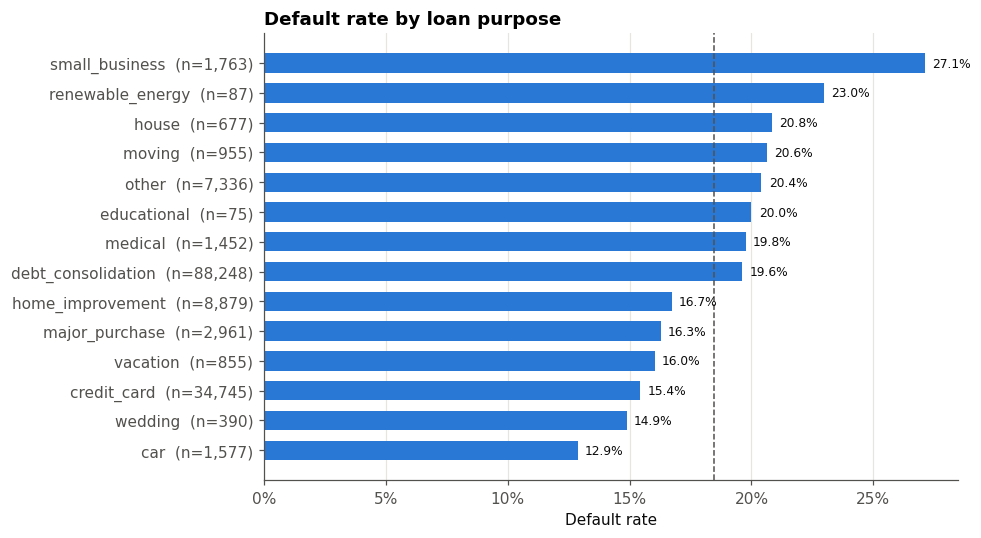

In [13]:
fig, ax = plt.subplots(figsize=(9, 5))
rate_bars(ax, rate_table(df, "purpose").sort_values("rate"), "Default rate by loan purpose", horizontal=True)
plt.tight_layout(); plt.show()

Small-business loans default at 27%, about twice the rate of car loans; debt consolidation sits right around the average at 20%, so purpose matters mostly at the tails.

### 5.3 Home ownership

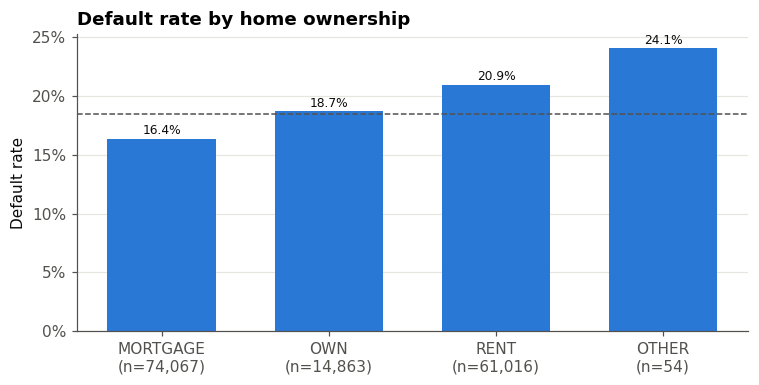

In [14]:
fig, ax = plt.subplots(figsize=(7, 3.6))
rate_bars(ax, rate_table(df, "home_ownership_n").loc[["MORTGAGE", "OWN", "RENT", "OTHER"]], "Default rate by home ownership")
plt.tight_layout(); plt.show()

Renters default more often than mortgage holders, with outright owners in between; the OTHER group is only 54 loans and should be merged.

### 5.4 Issue year

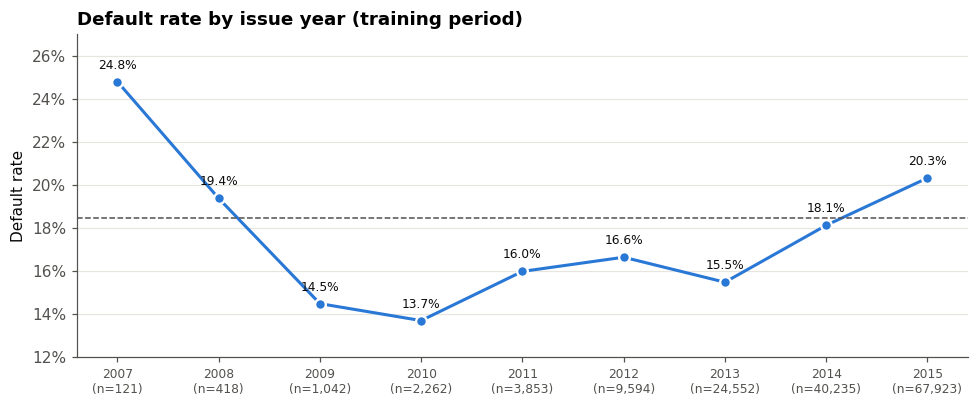

In [15]:
t = rate_table(df, "year")
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(range(len(t)), t.rate, color=BLUE, lw=2, marker="o", ms=7, mec="white", mew=1.5)
ax.axhline(BASE_RATE, color=MUTED, ls="--", lw=1)
ax.set_xticks(range(len(t)), [f"{y}\n(n={n:,})" for y, n in zip(t.index, t.n)], fontsize=8)
for x, r in enumerate(t.rate): ax.text(x, r + .006, f"{r:.1%}", ha="center", fontsize=8, color=INK)
ax.set_ylim(.12, .27); ax.yaxis.set_major_formatter(pct); ax.set_ylabel("Default rate"); ax.grid(axis="x", visible=False)
ax.set_title("Default rate by issue year (training period)")
plt.tight_layout(); plt.show()

After the 2007–08 crisis years, the default rate bottoms out near 14% in 2009–2010 and then climbs every year to 20% in 2015, heading toward the 23% seen in the 2016 test period, so the test set will be harder than the training data. Early years have few loans, so their rates are noisy.

## 6. Other drivers worth knowing

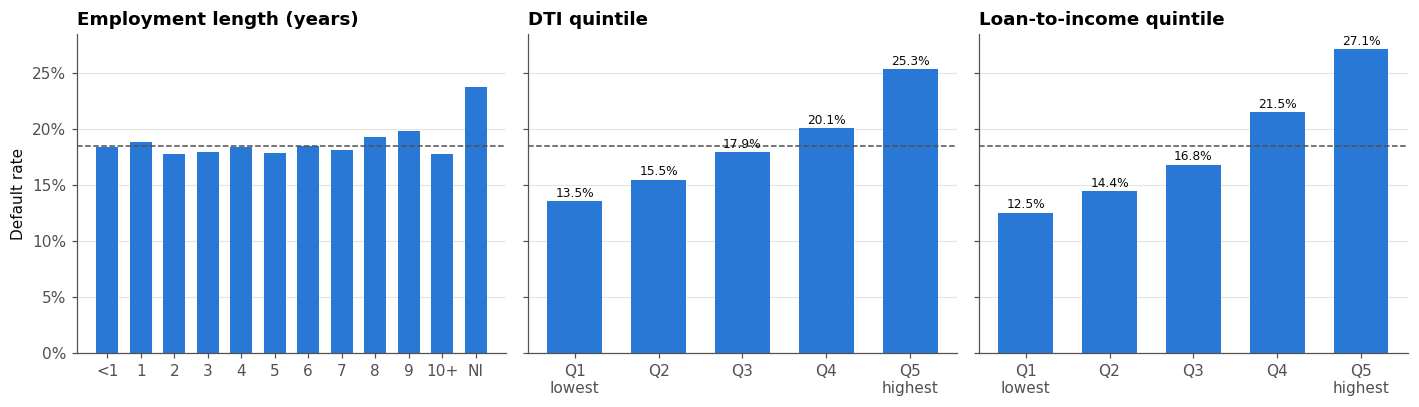

In [16]:
df["loan_to_income"] = df.loan_amnt / df.revenue
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
order = ["< 1 year"] + [f"{i} year{'s' if i > 1 else ''}" for i in range(1, 10)] + ["10+ years", "NI"]
rate_bars(axes[0], rate_table(df, "emp_length").loc[order], "Employment length (years)", annotate=False)
axes[0].set_xticks(range(len(order)), ["<1"] + [str(i) for i in range(1, 10)] + ["10+", "NI"])
for ax, col, name in [(axes[1], "dti_n", "DTI quintile"), (axes[2], "loan_to_income", "Loan-to-income quintile")]:
    t = df.groupby(pd.qcut(df[col], 5, labels=["Q1\nlowest", "Q2", "Q3", "Q4", "Q5\nhighest"]), observed=True).Default.agg(rate="mean", n="size")
    rate_bars(ax, t, name); ax.set_xticks(range(5), t.index)
for ax in axes[1:]: ax.set_ylabel("")
plt.tight_layout(); plt.show()

Employment length is flat for everyone who reported it — only "NI" stands out at 24%. By contrast, default rate climbs steadily with DTI and even more with loan-to-income, a wider spread than income or loan amount gives on its own, which is strong support for engineering the **loan-to-income** feature.

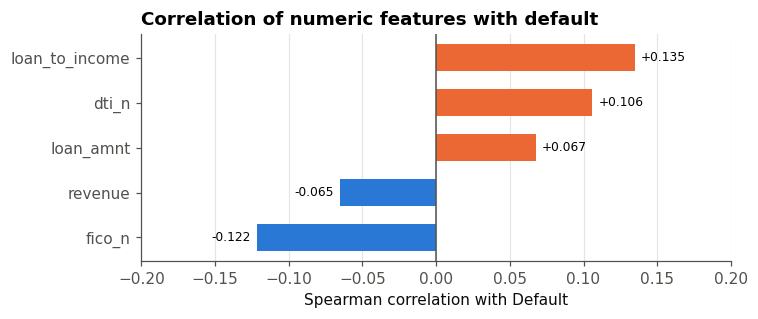

,fico_n,dti_n,revenue,loan_amnt,loan_to_income,Default
fico_n,1.00,-0.05,0.12,0.14,0.04,-0.12
dti_n,-0.05,1.00,-0.21,0.04,0.25,0.11
revenue,0.12,-0.21,1.00,0.50,-0.32,-0.07
loan_amnt,0.14,0.04,0.50,1.00,0.60,0.07
loan_to_income,0.04,0.25,-0.32,0.60,1.00,0.14
Default,-0.12,0.11,-0.07,0.07,0.14,1.00


In [17]:
num = df[["fico_n", "dti_n", "revenue", "loan_amnt", "loan_to_income", "Default"]]
corr = num.corr(method="spearman")
target_corr = corr["Default"].drop("Default").sort_values()
fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(target_corr.index, target_corr.values, color=[ORANGE if v > 0 else BLUE for v in target_corr], height=0.6)
ax.axvline(0, color=MUTED, lw=1); ax.grid(axis="y", visible=False)
for y, v in enumerate(target_corr): ax.text(v + (.004 if v > 0 else -.004), y, f"{v:+.3f}", va="center", ha="left" if v > 0 else "right", fontsize=8)
ax.set_xlim(-.2, .2); ax.set_xlabel("Spearman correlation with Default")
ax.set_title("Correlation of numeric features with default")
plt.tight_layout(); plt.show()
corr.round(2)

Every numeric feature is only weakly correlated with default (|ρ| ≤ 0.14), with loan-to-income the strongest, then FICO and DTI, which is realistic for credit data, and a sign there is **no leakage** (no suspiciously perfect predictor). Among the features, loan amount and loan-to-income are correlated (ρ = 0.60) and income and loan amount moderately so (0.50), which matters for linear-model coefficients but not for trees.

## 7. Hand-off to the pipeline (notebook 03)

All of these steps should be fitted on the training data only, inside the sklearn Pipeline.

| Column | EDA finding | Recommended action |
|---|---|---|
| `id` | Identifier | Drop |
| `issue_d` | Used to split by time | Drop as a feature |
| `revenue` | Skew ≈ 46, max $9.5M | Cap at 99.9th pct, then log |
| `dti_n` | 13 loans > 40%, max 83% | Cap at 99.9th pct |
| `loan_amnt` | Weak alone | Keep; use in loan-to-income |
| `fico_n` | Strongest predictor; floor at ~660 | Keep (optional FICO bands) |
| `experience_c` | 5 of 150k are 0 | Drop |
| `emp_length` | "NI" = 5.2%, riskier (23.7%) | Map to 0–10 years + `emp_missing` flag |
| `purpose` | 14 levels, 3 with < 500 loans | Merge rare levels, one-hot |
| `home_ownership_n` | OTHER = 54 loans | Merge OTHER into RENT, one-hot |
| `addr_state` | 50 levels, small-state noise | Smoothed target encoding or group |
| `zip_code` | 879 levels, 20% with < 30 loans | Drop |
| `title` | Free text, repeats purpose | Drop |
| `desc` | 86% missing, empty after 2014 | Drop |
| **new** `loan_to_income` | Default 13% → 27% across quintiles | Add |

**Limitations surfaced by EDA**
- Approved loans only: we never see rejected applicants, so the model only ranks risk *among people Lending Club already approved*.
- Income is self-reported and partly unverified, hence the extreme values.
- The default rate drifts upward over time, so performance on the 2016 test set may be lower than in cross-validation.